In [2]:
# Cell 1: Mount Drive and import the libraries used by this experiment.
from google.colab import drive
from pathlib import Path
from collections import defaultdict
import hashlib
import json
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image
import matplotlib.pyplot as plt

drive.mount('/content/drive')
print('TensorFlow:', tf.__version__)
print('Available GPUs:', tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
TensorFlow: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# Cell 2: Select this member's dataset, model, and new output folder.
PROJECT_DIR = Path('/content/drive/MyDrive/Research/Model_Training')  # Update only if this shared Drive is mounted elsewhere.
IMAGE_ROOT = PROJECT_DIR / "Caries_Dataset/Caries_Intraoral"
MANIFEST_PATH = PROJECT_DIR / 'Caries_Dataset/PP1_Final/Intraoral/manifests/alphadent_binary.csv'

TASK = 'caries_intraoral'
MODEL_NAME = 'MobileNetV2'
MODE = 'binary'
CLASS_NAMES = ['no_caries', 'caries']
PATIENT_GROUPED = True
SOURCE_MARKER = 'Caries_Intraoral'
RESIZE_MODE = 'stretch'
USE_AUGMENTATION = False
TEST_SPLIT = 'test'
RUN_ID = 'v1'  # Change to 'v2' for a genuinely new training run.
OUTPUT_DIR = PROJECT_DIR / 'outputs/comparator_runs' / f'{TASK}_{MODEL_NAME}_{RUN_ID}'

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42
EPOCHS_FROZEN = 15
EPOCHS_FINE = 8
UNFREEZE_LAST = 30
USE_CLASS_WEIGHTS = True
FROZEN_LR = 1e-3
FINE_LR = 1e-5
TARGET_SENSITIVITY = 0.80  # A validation-only threshold review target for binary tasks.

assert PROJECT_DIR.is_dir(), f'Project folder missing: {PROJECT_DIR}'
assert IMAGE_ROOT.is_dir(), f'Image folder missing: {IMAGE_ROOT}'
assert MANIFEST_PATH.is_file(), f'Manifest missing: {MANIFEST_PATH}'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)
run_settings = {
    'task': TASK, 'architecture': MODEL_NAME, 'manifest': str(MANIFEST_PATH),
    'manifest_sha256': hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest(),
    'classes': CLASS_NAMES, 'resize': RESIZE_MODE, 'augmentation': USE_AUGMENTATION,
    'class_weights': USE_CLASS_WEIGHTS, 'seed': SEED, 'image_size': IMG_SIZE,
    'batch_size': BATCH_SIZE, 'frozen_lr': FROZEN_LR, 'fine_lr': FINE_LR,
    'frozen_epochs': EPOCHS_FROZEN, 'fine_epochs': EPOCHS_FINE,
    'unfreeze_last': UNFREEZE_LAST,
}
settings_path = OUTPUT_DIR / 'initial_settings.json'
if settings_path.is_file():
    assert json.loads(settings_path.read_text()) == json.loads(json.dumps(run_settings)), (
        'This RUN_ID already has different settings. Pick a new RUN_ID for a new experiment.')
else:
    settings_path.write_text(json.dumps(run_settings, indent=2))
print('Manifest:', MANIFEST_PATH)
print('Image root:', IMAGE_ROOT)
print('New output directory:', OUTPUT_DIR)


Manifest: /content/drive/MyDrive/Research/Model_Training/Caries_Dataset/PP1_Final/Intraoral/manifests/alphadent_binary.csv
Image root: /content/drive/MyDrive/Research/Model_Training/Caries_Dataset/Caries_Intraoral
New output directory: /content/drive/MyDrive/Research/Model_Training/outputs/comparator_runs/caries_intraoral_MobileNetV2_v1


In [4]:
# Validate manifest fields and keep only training/validation rows for the current run.
df = pd.read_csv(MANIFEST_PATH)
required = {'image_id', 'split', 'target'}
assert not required.difference(df.columns), f'Missing columns: {required.difference(df.columns)}'
assert not df['image_id'].duplicated().any(), 'Duplicate image_id values in manifest'
df['split'] = df['split'].astype(str).str.strip().str.lower()
df['target'] = pd.to_numeric(df['target'], errors='raise').astype(int)
expected = set(range(len(CLASS_NAMES)))
assert set(df['target'].unique()).issubset(expected), 'Unexpected target number'
assert set(df['split'].unique()).issubset({'train', 'validation', TEST_SPLIT}), 'Unexpected split name'
assert {'train', 'validation', TEST_SPLIT}.issubset(set(df['split'])), 'A required split is absent'

if PATIENT_GROUPED:
    assert 'patient_id' in df.columns, 'Expected patient_id for patient-level auditing'
    assert df['patient_id'].notna().all(), 'Missing patient IDs in a patient-level split'
    assert df.groupby('patient_id')['split'].nunique().max() == 1, 'Patient appears in multiple splits'
    print('Patient overlap across splits: none')
else:
    print('Patient IDs unavailable: this split is image-level only.')

train_df = df.loc[df['split'].eq('train')].copy()
val_df = df.loc[df['split'].eq('validation')].copy()
assert set(train_df['target'].unique()) == expected, 'Training split lacks a class'
assert len(val_df) > 0, 'Validation split is empty'
assert set(val_df['target'].unique()) == expected, 'Validation split lacks a class'
print('Training counts:', train_df['target'].value_counts().sort_index().to_dict())
print('Validation counts:', val_df['target'].value_counts().sort_index().to_dict())
print('Held-out split:', TEST_SPLIT, '| rows:', df['split'].eq(TEST_SPLIT).sum())


Patient overlap across splits: none
Training counts: {0: 328, 1: 708}
Validation counts: {0: 19, 1: 64}
Held-out split: test | rows: 201


In [5]:
# Match only training/validation rows to source images; leave test images unopened.
by_name, by_stem = defaultdict(list), defaultdict(list)
allowed_ext = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
for path in IMAGE_ROOT.rglob('*'):
    if path.is_file() and path.suffix.lower() in allowed_ext:
        by_name[path.name.casefold()].append(path)
        by_stem[path.stem.casefold()].append(path)

def resolve_one(row):
    if 'image_path' in row.index and pd.notna(row['image_path']):
        raw = Path(str(row['image_path']))
        if raw.is_file():
            return raw
        if SOURCE_MARKER and SOURCE_MARKER in raw.parts:
            suffix = raw.parts[raw.parts.index(SOURCE_MARKER) + 1:]
            candidate = IMAGE_ROOT.joinpath(*suffix)
            if candidate.is_file():
                return candidate
        if not raw.is_absolute() and (IMAGE_ROOT / raw).is_file():
            return IMAGE_ROOT / raw
        matches = by_name.get(raw.name.casefold(), [])
    else:
        name = Path(str(row['image_id'])).name.casefold()
        matches = by_name.get(name, [])
        if not matches:
            matches = by_stem.get(Path(name).stem.casefold(), [])
    matches = sorted(set(matches))
    if len(matches) != 1:
        raise ValueError(f"Image {row['image_id']}: {len(matches)} candidate files: {matches[:4]}")
    return matches[0]

def attach_paths(frame):
    frame = frame.copy()
    frame['resolved_path'] = [str(resolve_one(row)) for _, row in frame.iterrows()]
    assert frame['resolved_path'].is_unique, 'Same image path mapped to multiple manifest rows'
    bad = []
    for image_id, path in zip(frame['image_id'], frame['resolved_path']):
        try:
            with Image.open(path) as image:
                image.load()
                image.convert('RGB').load()
        except Exception as exc:
            bad.append((image_id, str(path), str(exc)))
    if bad:
        raise ValueError(f'{len(bad)} unreadable images. Examples: {bad[:5]}')
    return frame

train_df = attach_paths(train_df)
val_df = attach_paths(val_df)
assert not set(train_df['resolved_path']) & set(val_df['resolved_path']), 'Same file in train and validation'
print('Verified train images:', len(train_df), '| validation images:', len(val_df))


Verified train images: 1036 | validation images: 83


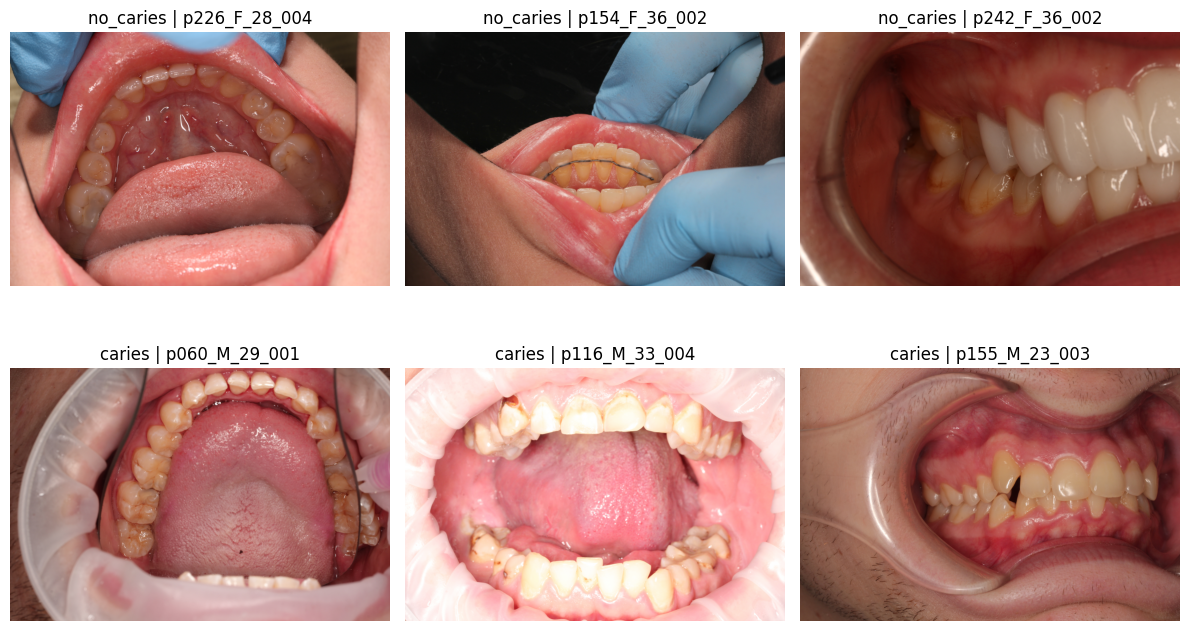

In [9]:
# Show up to three training images from each class.
samples = []
for class_id in range(len(CLASS_NAMES)):
    part = train_df.loc[train_df['target'].eq(class_id)]
    samples.append(part.sample(min(3, len(part)), random_state=SEED))
view = pd.concat(samples, ignore_index=True)
columns = 3
rows = int(np.ceil(len(view) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(12, 3.7 * rows))
axes = np.atleast_1d(axes).ravel()
for ax, (_, row) in zip(axes, view.iterrows()):
    with Image.open(row['resolved_path']) as image:
        ax.imshow(image.convert('RGB'))
    ax.set_title(f"{CLASS_NAMES[int(row['target'])]} | {row['image_id']}")
    ax.axis('off')
for ax in axes[len(view):]:
    ax.axis('off')
plt.tight_layout()
plt.show()


In [6]:
# Preserve the baseline image pipeline while applying model-specific preprocessing.
APPLICATIONS = {
    'MobileNetV2': (keras.applications.MobileNetV2, keras.applications.mobilenet_v2.preprocess_input),
    'EfficientNetB0': (keras.applications.EfficientNetB0, keras.applications.efficientnet.preprocess_input),
    'ResNet50': (keras.applications.ResNet50, keras.applications.resnet50.preprocess_input),
}
APP, PREPROCESS = APPLICATIONS[MODEL_NAME]
AUTOTUNE = tf.data.AUTOTUNE
augmentation = keras.Sequential([
    layers.RandomRotation(0.03, fill_mode='reflect'),
    layers.RandomTranslation(0.02, 0.02, fill_mode='reflect'),
    layers.RandomZoom(0.05, fill_mode='reflect'),
    layers.RandomContrast(0.10),
], name='train_only_augmentation')

def make_dataset(frame, training=False):
    paths = frame['resolved_path'].astype(str).to_numpy()
    labels = frame['target'].astype('int32' if MODE == 'multiclass' else 'float32').to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)

    def load(path, label):
        raw = tf.io.read_file(path)
        image = tf.io.decode_image(raw, channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.cast(image, tf.float32)
        if RESIZE_MODE == 'pad':
            image = tf.image.resize_with_pad(image, *IMG_SIZE)
        else:
            image = tf.image.resize(image, IMG_SIZE)
        if training and USE_AUGMENTATION:
            image = tf.clip_by_value(augmentation(image, training=True), 0.0, 255.0)
        image = PREPROCESS(image)
        if MODE == 'binary':
            label = tf.reshape(tf.cast(label, tf.float32), (1,))
        return image, label

    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
for batch_images, batch_labels in val_ds.take(1):
    print('Validation input shape:', batch_images.shape)
    print('Preprocessed pixel range:', float(tf.reduce_min(batch_images)), float(tf.reduce_max(batch_images)))
    print('Label shape:', batch_labels.shape)


Validation input shape: (16, 224, 224, 3)
Preprocessed pixel range: -1.0 1.0
Label shape: (16, 1)


In [7]:
# Train a new task-specific classification head on a frozen ImageNet backbone.
backbone = APP(include_top=False, weights='imagenet', input_shape=(*IMG_SIZE, 3))
backbone_name = backbone.name
backbone.trainable = False
inputs = keras.Input(shape=(*IMG_SIZE, 3), name='preprocessed_image')
features = backbone(inputs, training=False)
features = layers.GlobalAveragePooling2D()(features)
features = layers.Dropout(0.30)(features)
if MODE == 'binary':
    outputs = layers.Dense(1, activation='sigmoid', name='positive_probability')(features)
else:
    outputs = layers.Dense(len(CLASS_NAMES), activation='softmax', name='class_probabilities')(features)
model = keras.Model(inputs, outputs, name=f'{TASK}_{MODEL_NAME}')

def compile_model(current_model, learning_rate):
    if MODE == 'binary':
        loss = keras.losses.BinaryCrossentropy()
        metrics = [
            keras.metrics.BinaryAccuracy(name='accuracy'),
            keras.metrics.Precision(name='precision'),
            keras.metrics.Recall(name='recall'),
            keras.metrics.AUC(name='roc_auc'),
            keras.metrics.AUC(name='pr_auc', curve='PR'),
        ]
    else:
        loss = keras.losses.SparseCategoricalCrossentropy()
        metrics = [keras.metrics.SparseCategoricalAccuracy(name='accuracy')]
    current_model.compile(optimizer=keras.optimizers.Adam(learning_rate), loss=loss, metrics=metrics)

compile_model(model, FROZEN_LR)
counts = np.bincount(train_df['target'].to_numpy(), minlength=len(CLASS_NAMES))
assert np.all(counts > 0), f'Training class absent: {counts}'
class_weight = {i: len(train_df) / (len(CLASS_NAMES) * n) for i, n in enumerate(counts)}
print('Training class counts:', counts.tolist())
print('Training class weights:', class_weight if USE_CLASS_WEIGHTS else 'disabled')
print('Backbone:', backbone_name)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training class counts: [328, 708]
Training class weights: {0: np.float64(1.579268292682927), 1: np.float64(0.731638418079096)}
Backbone: mobilenetv2_1.00_224


In [ ]:
# Fit the head and retain the lowest-validation-loss frozen checkpoint.
frozen_path = OUTPUT_DIR / 'best_frozen.keras'
frozen_done = OUTPUT_DIR / 'frozen_complete.txt'
if frozen_done.exists():
    assert frozen_path.is_file(), 'Completion marker exists but frozen checkpoint is missing'
    assert (OUTPUT_DIR / 'frozen_history.csv').is_file(), 'Frozen CSV history is missing'
    print('Using completed frozen checkpoint:', frozen_path)
else:
    callbacks = [
        keras.callbacks.ModelCheckpoint(str(frozen_path), monitor='val_loss', save_best_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-7, verbose=1),
        keras.callbacks.CSVLogger(str(OUTPUT_DIR / 'frozen_history.csv')),
        keras.callbacks.BackupAndRestore(backup_dir=str(OUTPUT_DIR / 'frozen_backup')),
    ]
    history_frozen = model.fit(
        train_ds, validation_data=val_ds, epochs=EPOCHS_FROZEN,
        class_weight=class_weight if USE_CLASS_WEIGHTS else None,
        callbacks=callbacks, verbose=1,
    )
    frozen_done.write_text('complete')
assert frozen_path.is_file(), 'Frozen training did not create a checkpoint'
print('Frozen checkpoint:', frozen_path)


Epoch 1/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5022 - loss: 0.8118 - pr_auc: 0.6819 - precision: 0.6811 - recall: 0.4762 - roc_auc: 0.5221
Epoch 1: val_loss improved from None to 0.79947, saving model to /content/drive/MyDrive/Research/Model_Training/outputs/comparator_runs/caries_intraoral_MobileNetV2_v1/best_frozen.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Research/Model_Training/outputs/comparator_runs/caries_intraoral_MobileNetV2_v1/best_frozen.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 239s 3s/step - accuracy: 0.5512 - loss: 0.7747 - pr_auc: 0.7192 - precision: 0.7306 - recall: 0.5438 - roc_auc: 0.5583 - val_accuracy: 0.4458 - val_loss: 0.7995 - val_pr_auc: 0.7818 - val_precision: 0.8000 - val_recall: 0.3750 - val_roc_auc: 0.5736 - learning_rate: 0.0010
Epoch 2/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5710 - loss: 0.7101 - pr_auc: 0.7834 - precision: 0.7658 - recall: 0.5467 - roc_auc: 0.6227
Epoch 2: val_loss improved from 0.79947 to 0.650

In [8]:
frozen_path = OUTPUT_DIR / "best_frozen.keras"
history_path = OUTPUT_DIR / "frozen_history.csv"

print("Checkpoint exists:", frozen_path.is_file())
print("History exists:", history_path.is_file())

if frozen_path.is_file():
    saved_model = keras.models.load_model(frozen_path, compile=False)
    print("Saved frozen model loads successfully")

Checkpoint exists: True
History exists: True
Saved frozen model loads successfully


In [9]:
# Continue from the best frozen weights with small backbone updates.
fine_path = OUTPUT_DIR / 'best_finetuned.keras'
fine_done = OUTPUT_DIR / 'fine_complete.txt'
if fine_done.exists():
    assert fine_path.is_file(), 'Completion marker exists but fine-tuned checkpoint is missing'
    assert (OUTPUT_DIR / 'fine_history.csv').is_file(), 'Fine-tuned CSV history is missing'
    print('Using completed fine-tuned checkpoint:', fine_path)
else:
    fine_model = keras.models.load_model(frozen_path, compile=False)
    fine_backbone = next(layer for layer in fine_model.layers if isinstance(layer, keras.Model))
    fine_backbone.trainable = True
    cutoff = max(0, len(fine_backbone.layers) - UNFREEZE_LAST)
    for layer in fine_backbone.layers[:cutoff]:
        layer.trainable = False
    for layer in fine_backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    compile_model(fine_model, FINE_LR)
    callbacks = [
        keras.callbacks.ModelCheckpoint(str(fine_path), monitor='val_loss', save_best_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-7, verbose=1),
        keras.callbacks.CSVLogger(str(OUTPUT_DIR / 'fine_history.csv')),
        keras.callbacks.BackupAndRestore(backup_dir=str(OUTPUT_DIR / 'fine_backup')),
    ]
    history_fine = fine_model.fit(
        train_ds, validation_data=val_ds, epochs=EPOCHS_FINE,
        class_weight=class_weight if USE_CLASS_WEIGHTS else None,
        callbacks=callbacks, verbose=1,
    )
    fine_done.write_text('complete')
assert fine_path.is_file(), 'Fine-tuning did not create a checkpoint'
print('Fine-tuned checkpoint:', fine_path)


Epoch 2/8
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7319 - loss: 0.5525 - pr_auc: 0.8815 - precision: 0.8274 - recall: 0.7574 - roc_auc: 0.7953
Epoch 2: val_loss improved from None to 0.63012, saving model to /content/drive/MyDrive/Research/Model_Training/outputs/comparator_runs/caries_intraoral_MobileNetV2_v1/best_finetuned.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Research/Model_Training/outputs/comparator_runs/caries_intraoral_MobileNetV2_v1/best_finetuned.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 232s 3s/step - accuracy: 0.7317 - loss: 0.5328 - pr_auc: 0.8965 - precision: 0.8457 - recall: 0.7429 - roc_auc: 0.8066 - val_accuracy: 0.6145 - val_loss: 0.6301 - val_pr_auc: 0.8412 - val_precision: 0.8636 - val_recall: 0.5938 - val_roc_auc: 0.7093 - learning_rate: 1.0000e-05
Epoch 3/8
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7473 - loss: 0.4716 - pr_auc: 0.9267 - precision: 0.8611 - recall: 0.7541 - roc_auc: 0.8543
Epoch 3: val_loss improved from 0.63012 

In [10]:
# Select frozen versus fine-tuned weights using validation loss only.
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             average_precision_score, balanced_accuracy_score,
                             precision_score, recall_score, f1_score)

frozen_best = float(pd.read_csv(OUTPUT_DIR / 'frozen_history.csv')['val_loss'].min())
fine_best = float(pd.read_csv(OUTPUT_DIR / 'fine_history.csv')['val_loss'].min())
selected_stage = 'fine_tuned' if fine_best < frozen_best else 'frozen'
selected_source = fine_path if selected_stage == 'fine_tuned' else frozen_path
selected_model = keras.models.load_model(selected_source, compile=False)
selected_path = OUTPUT_DIR / 'selected_model.keras'
selected_model.save(selected_path)
y_true = val_df['target'].astype(int).to_numpy()
probabilities = selected_model.predict(val_ds, verbose=1)
print('Frozen/fine validation loss:', frozen_best, fine_best)
print('Selected stage:', selected_stage)

if MODE == 'binary':
    scores = probabilities.reshape(-1)
    predicted = (scores >= 0.5).astype(int)
    cm = confusion_matrix(y_true, predicted, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    summary = {
        'threshold': 0.5,
        'accuracy': float((tn + tp) / len(y_true)),
        'balanced_accuracy': float(balanced_accuracy_score(y_true, predicted)),
        'precision': float(precision_score(y_true, predicted, zero_division=0)),
        'sensitivity': float(recall_score(y_true, predicted, zero_division=0)),
        'specificity': float(tn / (tn + fp)) if tn + fp else None,
        'f1': float(f1_score(y_true, predicted, zero_division=0)),
        'confusion_matrix': cm.tolist(),
        'roc_auc': float(roc_auc_score(y_true, scores)) if len(set(y_true)) == 2 else None,
        'pr_auc_average_precision': float(average_precision_score(y_true, scores)) if len(set(y_true)) == 2 else None,
    }
    print('At threshold 0.5:', summary)
    print(classification_report(y_true, predicted, labels=[0, 1], target_names=CLASS_NAMES, zero_division=0))
    review = val_df[['image_id', 'resolved_path', 'target']].copy()
    review['positive_probability'] = scores
    review['prediction_0_5'] = predicted
    review.to_csv(OUTPUT_DIR / 'validation_predictions.csv', index=False)
    review.loc[(y_true == 0) & (predicted == 1)].to_csv(
        OUTPUT_DIR / 'validation_false_positives_for_review.csv', index=False)

    def at_threshold(threshold):
        pred = (scores >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        return {'threshold': float(threshold), 'sensitivity': float(tp / (tp + fn)),
                'specificity': float(tn / (tn + fp))}
    choices = [at_threshold(t) for t in np.unique(np.r_[0.0, scores, 1.0])]
    eligible = [m for m in choices if m['sensitivity'] >= TARGET_SENSITIVITY]
    summary['validation_threshold_candidate'] = max(
        eligible, key=lambda m: (m['specificity'], m['threshold'])) if eligible else None
    print('Threshold candidate (validation only):', summary['validation_threshold_candidate'])
else:
    predicted = np.argmax(probabilities, axis=1)
    cm = confusion_matrix(y_true, predicted, labels=list(range(len(CLASS_NAMES))))
    summary = {
        'accuracy': float(np.mean(predicted == y_true)),
        'macro_f1': float(f1_score(y_true, predicted, average='macro', zero_division=0)),
        'confusion_matrix': cm.tolist(),
    }
    if set(y_true) == set(range(len(CLASS_NAMES))):
        summary['roc_auc_ovr_macro'] = float(roc_auc_score(
            y_true, probabilities, multi_class='ovr', average='macro',
            labels=list(range(len(CLASS_NAMES)))))
        summary['pr_auc_per_class'] = {
            name: float(average_precision_score((y_true == i).astype(int), probabilities[:, i]))
            for i, name in enumerate(CLASS_NAMES)
        }
    print('Multiclass validation:', summary)
    print(classification_report(y_true, predicted,
          labels=list(range(len(CLASS_NAMES))), target_names=CLASS_NAMES, zero_division=0))
    review = val_df[['image_id', 'resolved_path', 'target']].copy()
    for i, name in enumerate(CLASS_NAMES):
        review['probability_' + name] = probabilities[:, i]
    review['prediction'] = predicted
    review.to_csv(OUTPUT_DIR / 'validation_predictions.csv', index=False)

report = {'task': TASK, 'architecture': MODEL_NAME, 'selected_stage': selected_stage,
          'frozen_best_val_loss': frozen_best, 'fine_best_val_loss': fine_best,
          'validation': summary, 'test_evaluated': False}
(OUTPUT_DIR / 'validation_summary.json').write_text(json.dumps(report, indent=2))
print('Saved validation summary and selected model:', OUTPUT_DIR)


6/6 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step
Frozen/fine validation loss: 0.5604780912399292 0.5588403940200806
Selected stage: fine_tuned
At threshold 0.5: {'threshold': 0.5, 'accuracy': 0.6987951807228916, 'balanced_accuracy': 0.638157894736842, 'precision': 0.8421052631578947, 'sensitivity': 0.75, 'specificity': 0.5263157894736842, 'f1': 0.7933884297520661, 'confusion_matrix': [[10, 9], [16, 48]], 'roc_auc': 0.699013157894737, 'pr_auc_average_precision': 0.8446259470993126}
              precision    recall  f1-score   support

   no_caries       0.38      0.53      0.44        19
      caries       0.84      0.75      0.79        64

    accuracy                           0.70        83
   macro avg       0.61      0.64      0.62        83
weighted avg       0.74      0.70      0.71        83

Threshold candidate (validation only): {'threshold': 0.4777980148792267, 'sensitivity': 0.8125, 'specificity': 0.5263157894736842}
Saved validation summary and selected model: /content/drive/MyDrive/

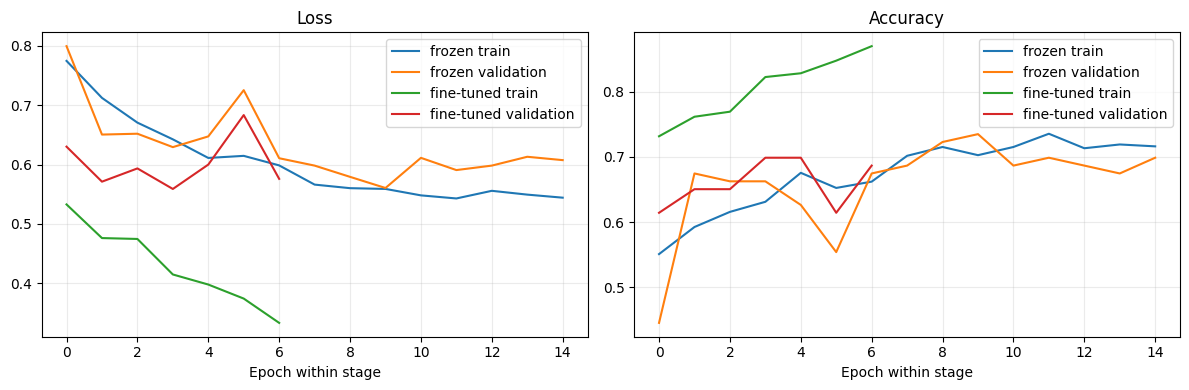

Saved model: /content/drive/MyDrive/Research/Model_Training/outputs/comparator_runs/caries_intraoral_MobileNetV2_v1/selected_model.keras
Integration needs the same RGB resize and preprocess operation in run_record.json


In [11]:
# Save learning curves and a concise record for this exact model run.
frozen_history = pd.read_csv(OUTPUT_DIR / 'frozen_history.csv')
fine_history = pd.read_csv(OUTPUT_DIR / 'fine_history.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for stage, history in [('frozen', frozen_history), ('fine-tuned', fine_history)]:
    for key, ax in [('loss', axes[0]), ('accuracy', axes[1])]:
        if key in history and 'val_' + key in history:
            ax.plot(history[key], label=f'{stage} train')
            ax.plot(history['val_' + key], label=f'{stage} validation')
for ax, title in zip(axes, ['Loss', 'Accuracy']):
    ax.set_title(title)
    ax.set_xlabel('Epoch within stage')
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'validation_curves.png', dpi=160)
plt.show()

manifest_sha256 = hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest()
record = {
    'task': TASK, 'architecture': MODEL_NAME, 'class_names': CLASS_NAMES,
    'manifest': str(MANIFEST_PATH), 'manifest_sha256': manifest_sha256,
    'patient_grouped': PATIENT_GROUPED, 'selected_stage': selected_stage,
    'saved_model': selected_path.name, 'image_size': list(IMG_SIZE),
    'color': 'RGB', 'resize': RESIZE_MODE, 'augmentation_training_only': USE_AUGMENTATION,
    'preprocess': MODEL_NAME + ' application preprocess_input',
    'saved_model_expects_preprocessed_input': True,
    'seed': SEED, 'batch_size': BATCH_SIZE,
    'class_weights_enabled': USE_CLASS_WEIGHTS,
    'frozen_lr': FROZEN_LR, 'fine_lr': FINE_LR,
    'train_images': len(train_df), 'validation_images': len(val_df),
    'test_split_reserved': TEST_SPLIT,
}
(OUTPUT_DIR / 'run_record.json').write_text(json.dumps(record, indent=2))
print('Saved model:', selected_path)
print('Integration needs the same RGB resize and preprocess operation in run_record.json')
